##### Command de instaler libs :
```bach
%pip install --no-cache-dir --force-reinstall typing_extensions==4.16.0
```
```bash
pip install numpy matplotlib seaborn scikit-learn opencv-python kagglehub 
```
```bach
pip install mlflow
```

# %pip install --upgrade typing_extensions
# %pip install "protobuf>=3.20.3,<6"

In [10]:
pip install numpy matplotlib seaborn scikit-learn opencv-python kagglehub mlflow

Note: you may need to restart the kernel to use updated packages.


In [1]:
from typing_extensions import Sentinel
import pydantic
import mlflow

print("typing_extensions OK")
print("pydantic:", pydantic.__version__)
print("mlflow:", mlflow.__version__)

typing_extensions OK
pydantic: 2.14.1
mlflow: 3.17.2


In [3]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import time
import cv2
import re

from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
from sklearn.metrics import f1_score

import tensorflow as tf
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input
from tensorflow.keras import layers
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import GlobalAveragePooling2D, Dropout, Dense
from tensorflow.keras.callbacks import ModelCheckpoint, BackupAndRestore, EarlyStopping
from tensorflow.keras.utils import to_categorical
import mlflow
from mlflow import MlflowClient
import kagglehub

RANDOM_KEY=26
SIZE_IMAGE=224
BATCH_SIZE = 45
EPOCHS = 30
AUTOTUNE = tf.data.AUTOTUNE
EARLY_STOPPING_PATIENCE = 15

DATA_DIR = Path(kagglehub.dataset_download("karapy/neurovision") + '/Data')
print(DATA_DIR)

100%|██████████| 149M/149M [00:10<00:00, 14.3MB/s] 

Extracting files...


/root/.cache/kagglehub/datasets/karapy/neurovision/versions/1/Data


#### Charger les images

In [4]:
def loead_images(data_dire:str):
    images = []
    labels = []

    extention_allow = {".jpeg", ".jpg", ".bmp", ".png"}

    for folder in Path(data_dire).iterdir():
        if not folder.is_dir():
            continue

        label = folder.name

        for file in folder.iterdir():
            if file.suffix.lower() not in extention_allow:
                continue

            images.append(str(file))
            labels.append(label)
    return images, labels

images_path, labels = loead_images(DATA_DIR)


print("Nomber d'images :", len(images_path))
print("Nomber de labels :", len(labels))

print('Example de image:', images_path[0])
print('Example de Label:', labels[0])

Nomber d'images : 7023
Nomber de labels : 7023
Example de image: /root/.cache/kagglehub/datasets/karapy/neurovision/versions/1/Data/glioma/Te-glTr_0000.jpg
Example de Label: glioma


#### Convertir les listes en tableaux NumPy

In [5]:
def convert_to_numpay_table(images, labels):
    return np.array(images), np.array(labels)

X, y = convert_to_numpay_table(images_path, labels)

#### Afficher un échantillon d'images

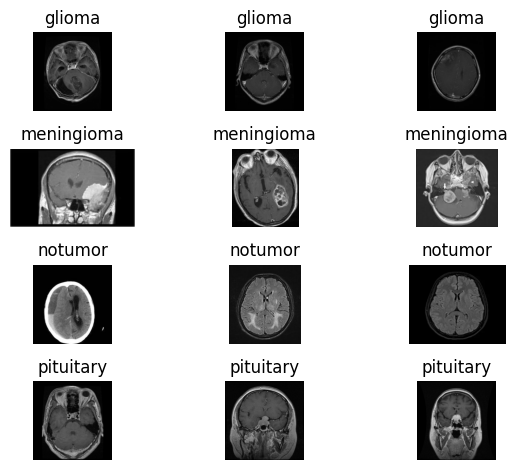

In [6]:
def afficher_images_echntillon(images, labels):
    classes = np.unique(labels)
    _, axes = plt.subplots(len(classes), 3)

    for i, classe in enumerate(classes):
        images_index = np.where(labels == classe)[0][:3]
        for j, index in enumerate(images_index):
            # loead et converter BGR to RGB
            image = cv2.cvtColor(cv2.imread(images[index]), cv2.COLOR_BGR2RGB)
            axes[i, j].imshow(image)
            axes[i, j].set_title(classe)
            axes[i, j].axis('off')
    plt.tight_layout()
    plt.show()

classes = np.unique(y)

afficher_images_echntillon(X, y)

#### Afficher la distribution et l'équilibre des images

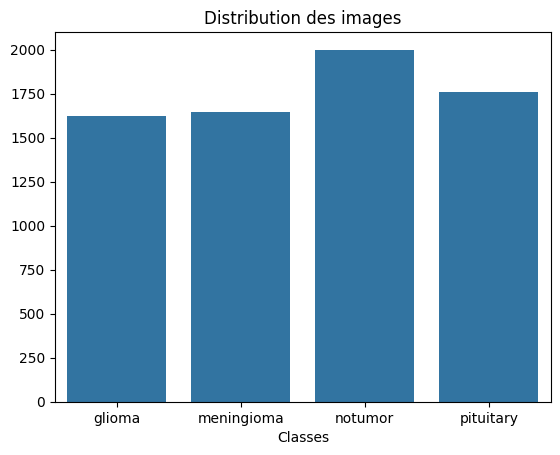

In [7]:
def afficher_distribution_classes(labels):
    classes, counts = np.unique(labels, return_counts=True)
    plt.figure()
    sns.barplot(x=classes, y=counts)
    plt.title('Distribution des images')
    plt.xlabel('Classes')
    plt.show()

afficher_distribution_classes(y)

#### Appliquer Label Encoging 

In [8]:
def applay_encoding(list):
    encoder = LabelEncoder()
    return encoder.fit_transform(list), encoder

y_encoder, label_encoder = applay_encoding(y)

num_classes = len(np.unique(y_encoder))

print(num_classes)

4


#### Split data

In [11]:
# Split test and train
X_temp, X_test, y_temp, y_test = train_test_split(
    X,
    y_encoder, 
    test_size=0.3,
    stratify=y_encoder,
    random_state=RANDOM_KEY
)

# Split validation
X_train, X_val, y_train, y_val = train_test_split(
    X_temp,
    y_temp,
    test_size=0.2,
    stratify=y_temp,
    random_state=RANDOM_KEY
)

print("Train :", len(X_train))
print("Validation :", len(X_val))
print("Test :", len(X_test))

Train : 3932
Validation : 984
Test : 2107


#### Appliquer One-Hot Encoding

In [12]:
y_train = to_categorical(y_train, num_classes=num_classes)
y_val = to_categorical(y_val, num_classes=num_classes)
y_test = to_categorical(y_test, num_classes=num_classes)

#### Data augmentation

In [13]:
data_augmentation = tf.keras.Sequential([
    layers.RandomRotation(0.03),
    layers.RandomZoom(0.1),
    layers.RandomTranslation(
        height_factor=0.05,
        width_factor=0.05
    )
])

I0000 00:00:1792939137.049858    1933 gpu_device.cc:2019] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 10260 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 3060, pci bus id: 0000:05:00.0, compute capability: 8.6


#### Exemple des images avec augmentation

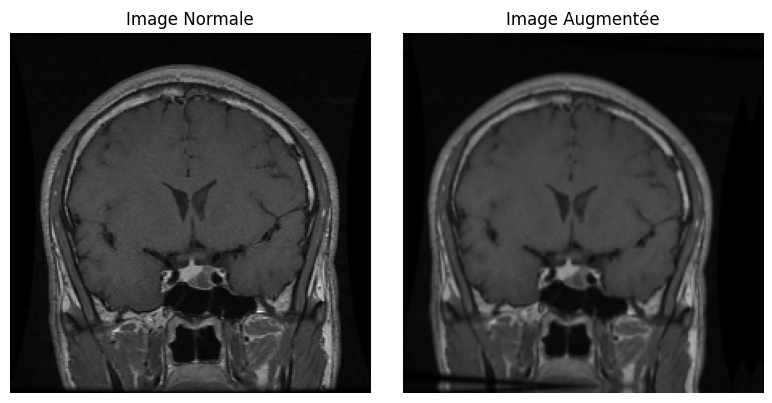

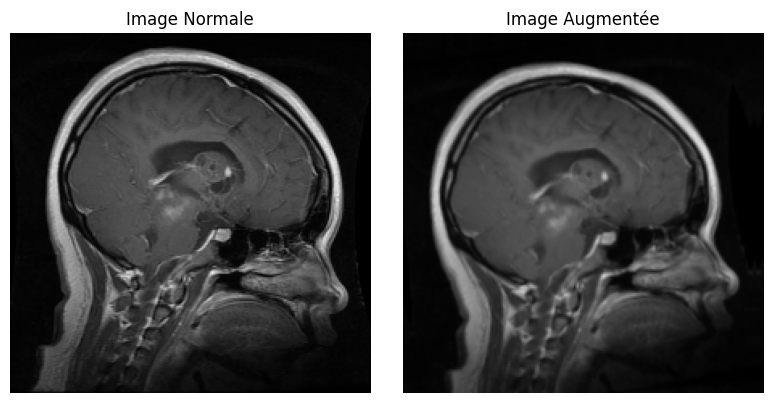

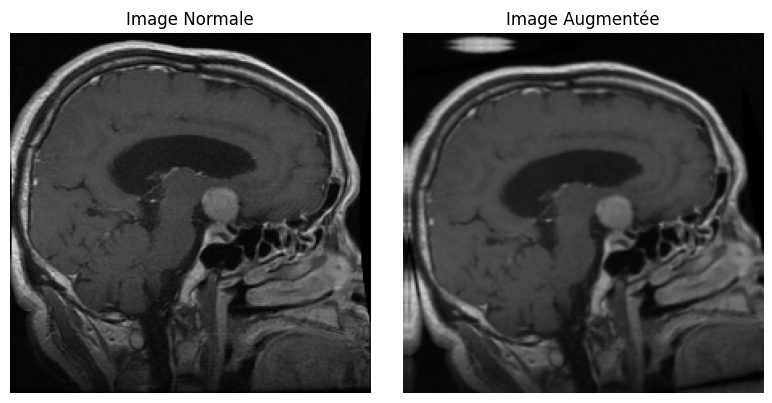

In [14]:
def afficher_images_augmentation(image_path, data_augmentation):
    # Loader l'image avec OpenCV et converter à RGB
    image = cv2.imread(image_path)

    if image is None:
        print(f"Erreur de chargement : {image_path}")
        return
    
    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
    image = cv2.resize(image, (SIZE_IMAGE, SIZE_IMAGE))

    # 2. Ajouter batch dimension pour keras (1, H, W, C)
    image_batch = tf.cast(image, tf.float32)
    image_batch = tf.expand_dims(image_batch, axis=0)

    # Appliquer l'augmentation
    image_augmentee_batch = data_augmentation(image_batch, training=True)

    # Supprimer dimension et converter à uint8 pour afficher avec Matplotlib
    image_augmentee = tf.squeeze(image_augmentee_batch, axis=0)
    image_augmentee = tf.clip_by_value(image_augmentee, 0, 255)
    image_augmentee = image_augmentee.numpy().astype("uint8")

    # Affichage
    plt.figure(figsize=(8, 4))
    
    plt.subplot(1, 2, 1)
    plt.imshow(image)
    plt.title("Image Normale")
    plt.axis('off')

    plt.subplot(1, 2, 2)
    plt.imshow(image_augmentee)
    plt.title("Image Augmentée")
    plt.axis('off')

    plt.tight_layout()
    plt.show()

for i in range(3):
    afficher_images_augmentation(X_train[i], data_augmentation)

#### TensorFlow Dataset

In [15]:
# Create dataset avec params
def create_dataset(x_data, y_data, normalize_collback, is_use_shuffle = False):
    dataset = (
        tf.data.Dataset
            .from_tensor_slices((x_data, y_data))
            .map(
                lambda image_path, label: load_image(image_path, label, normalize_collback),
                num_parallel_calls=AUTOTUNE
            )
    )

    # Shuffle les donnes
    if is_use_shuffle:
        dataset.shuffle(
            buffer_size=len(x_data), # pour utiliser tout les donnes dans mélange
            seed=RANDOM_KEY # Randomize logic
        )

    return dataset.batch(BATCH_SIZE).prefetch(AUTOTUNE) # Pour preparer les batch en paralille


# Load image and resize and normalize
def load_image(filename, label, normalize_collback):
    # load image
    raw = tf.io.read_file(filename)

    # converter image à matric de tensors avec 3 channels
    image = tf.image.decode_image(raw, channels=3)
    image.set_shape([None, None, 3]) # Déclarer le size image pour éviter error
    
    # Resize
    image = tf.image.resize(image, [SIZE_IMAGE, SIZE_IMAGE])

    # Normalization pour Base model
    image  = normalize_collback(image)
    return image, label

#### Visualiser les courbes d'apprentissage

In [16]:
def afficher_courbes_apprentissage(history):
    # Accuracy
    plt.figure(figsize=(12, 4))

    plt.subplot(1, 2, 1)
    plt.plot(history["accuracy"], label="Accuracy - Train")
    plt.plot(history["val_accuracy"], label="Accuracy - Validation")

    plt.title("Accuracy")
    plt.xlabel("Epoch")
    plt.ylabel("Accuracy")
    plt.legend()

    # Loss
    plt.subplot(1, 2, 2)
    plt.plot(history["loss"], label="Loss - Train")
    plt.plot(history["val_loss"], label="Loss - Validation")

    plt.title("Loss")
    plt.xlabel("Epoch")
    plt.ylabel("Loss")
    plt.legend()

    plt.tight_layout()
    plt.show()

#### Evaluate model

In [17]:
def evaluate_model(model, test_ds, model_path ,y_test, name, label_encoder):
    # Predire les probabilites sur le dataset de test
    y_pred_probs = model.predict(test_ds, verbose=0) # Probabiliter sur les 4 classes
    # print(y_pred_probs[0])

    # Recuperer la classe avec la probabilite maximale
    y_pred = np.argmax(y_pred_probs, axis=1) # index de max proba sur les column 

    # Convertir les labels one-hot en numeros de classes
    y_true = np.argmax(y_test, axis=1) # convert One hot encoding à label encoded

    # Evaluer sur le dataset de test
    test_loss, test_accuracy = model.evaluate(test_ds, verbose=1)

    f1 = f1_score(y_true, y_pred, average='macro')

    # Enregistrer les metriques dans MLflow
    mlflow.log_metric("test_loss", float(test_loss))
    mlflow.log_metric("test_accuracy", float(test_accuracy))
    mlflow.log_metric("test_f1_score", float(f1))

    print(
        f"Resultats : Loss={test_loss:.4f} | "
        f"Accuracy={test_accuracy:.4f} | "
        f"F1-score={f1:.4f}"
    )

    # ================= MATRICE DE CONFUSION =================
    classes = label_encoder.classes_

    cm = confusion_matrix(
        y_true, 
        y_pred,
        labels=np.arange(len(classes))
    )

    display = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=classes
    )

    display.plot(cmap="Blues", xticks_rotation=45)
    plt.title("Matrice de confusion")
    plt.tight_layout()

    # Sauvegarder l'image
    cm_path = f"{model_path}/confusion_matrix.png"
    plt.savefig(cm_path, dpi=300, bbox_inches="tight")

    # Enregistrer dans MLflow comme artifact
    mlflow.log_artifact(cm_path, artifact_path="evaluation")

    plt.show()

    # ================= RAPPORT DE CLASSIFICATION =================
    # Generer le rapport
    report = classification_report(
        y_true,
        y_pred,
        labels=np.arange(len(classes)),
        target_names=classes,
        zero_division=0
    )

    print(report)

    # Sauvegarder le rapport dans un fichier TXT
    report_path = f"{model_path}/classification_report.txt"

    with open(report_path, "w", encoding="utf-8") as file:
        file.write(report)

    # Enregistrer dans MLflow comme artifact
    mlflow.log_artifact(
        report_path,
        artifact_path="evaluation"
    )

    # ================= ENREGISTREMENT MLFLOW =================
    mlflow.tensorflow.log_model(
        model=model,
        name=name,
        registered_model_name=name
    )


#### CNN model

In [18]:
def build_cnn_model(x_train, y_train, x_val, y_val, x_test,y_test, data_augmentation, label_encoder):
    normalize_collback = lambda image: image / 255
    # ================= DATASETS =================
    # Trian
    train_ds = create_dataset(
        x_train,
        y_train,
        normalize_collback= normalize_collback,
        is_use_shuffle=True
    )

    # Validation 
    val_ds = create_dataset(x_val, y_val, normalize_collback)

    # Test
    test_ds = create_dataset(x_test, y_test, normalize_collback)

    # ================= DOSSIER =================
    model_path = f"output/models/cnn"
    Path(model_path).mkdir(parents=True, exist_ok=True)

    # Architecture Sequential
    model = Sequential([
        # Layer Inpute
        layers.Input(shape=(224, 224, 3)),
        
        # Appliquer une augmentation
        data_augmentation,

        # Convolaton layer 1
        layers.Conv2D(32, (3, 3), activation="relu"),
        layers.MaxPooling2D((2, 2)),

        # Convolaton layer 2
        layers.Conv2D(64, (3, 3), activation="relu"),
        layers.MaxPooling2D((2, 2)),
        layers.Dropout(0.25),

        # Convolaton layer 3
        layers.Conv2D(128, (3, 3), activation="relu"),
        layers.MaxPooling2D((2, 2)),
        layers.Dropout(0.25),

        # Flatten
        layers.Flatten(),

        # Hidden layers
        layers.Dense(128, activation="relu"),
        layers.Dropout(0.5),

        layers.Dense(64, activation="relu"),
        layers.Dropout(0.5),

        # Classification
        layers.Dense(4, activation="softmax")
    ])

    model.summary()

    # Compilation du modele
    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=0.001), # Optimizer avec learninig rate
        loss="categorical_crossentropy",
        metrics=["accuracy"]
    )

    # Callbacks du Transfer Learning
    callbacks_cnn = [
        # Suvgarder le baset model pendant le training
        ModelCheckpoint(
            filepath=f"{model_path}/best_model_cnn.keras", # path de bast model
            monitor="val_loss", # monitore de comparisent
            save_best_only=True, # Sauvgarder le baset model sulment
            mode="min", # Suavgarder le model de min monitor
            verbose=1 # afficher sur terminal
        ),
        # Sauvgarder le étap de train si ariter pour pas perdet le étap de training
        BackupAndRestore(
            backup_dir=f"{model_path}/backup_cnn" # dosser de sauvgarder
        ),
        # Limiter le surapprentissage
        EarlyStopping(
            monitor="val_loss", # monitore de comparisent
            patience=EARLY_STOPPING_PATIENCE, # nomber des epochs sans augmentation de monitor
            restore_best_weights=True, # returner baset weights
            mode="min", # minimuent monitor
            verbose=1
        )
    ]

    # ================= RUN 1 : TRANSFER LEARNING =================

    with mlflow.start_run(run_name=f"cnn_feature_extraction"):
        mlflow.log_params({
            "model_name": 'cnn',
            "batch_size": BATCH_SIZE,
            "epochs": EPOCHS,
            "image_size": SIZE_IMAGE,
            "learning_rate": 0.001,
        })

        print('\n========= Training =========\n')

        # Entrainement du CNN Learning
        start_time = time.time()

        cnn_history = model.fit(
            train_ds,
            validation_data=val_ds,
            epochs=EPOCHS,
            callbacks=callbacks_cnn
        )

        train_time = time.time() - start_time

        # Enregistrer les mtrics
        mlflow.log_metric("training_duration_seconds", train_time)

        print(f"Temps d'entraînement en CNN learning : {train_time / 60:.2f} minute")

        # ================= EVALUATION =================
        evaluate_model(model, test_ds, model_path, y_test, 'cnn', label_encoder)

        # ================= COURBES =================
        afficher_courbes_apprentissage(cnn_history.history)

#### Transfer model

In [19]:
def build_transfer_model(base_model, normalize_collback, x_train, y_train, x_val, y_val, x_test,y_test, data_augmentation, label_encoder):
    # Charger le modele pre-entraine
    base = base_model(
        weights='imagenet', # loader les weights of train imagenet
        include_top=False, # remove classes of predicts base
        input_shape=(SIZE_IMAGE, SIZE_IMAGE, 3) # Size of input
    )

    # ================= DATASETS =================
    # Trian
    train_ds = create_dataset(x_train, y_train, normalize_collback= normalize_collback, is_use_shuffle=True)

    # Validation 
    val_ds = create_dataset(x_val, y_val, normalize_collback)

    # Test
    test_ds = create_dataset(x_test, y_test, normalize_collback)

    # ================= DOSSIER =================
    model_name = re.sub(r'[/:.%"\']', '_', base.name)

    model_path = f"output/models/{model_name}"
    Path(model_path).mkdir(parents=True, exist_ok=True)

    # ================= TRANSFER LEARNING (Inference) =================
    
    base.trainable = False # franze all parametres of base model to not chnager on training

    # Architecture Sequential
    model = Sequential([
        # Appliquer augmentation
        data_augmentation,

        base, # Extraire les caractéristiques en mode inference

        GlobalAveragePooling2D(), # minimizer les Featurs Map à vectore 

        # hiden layer
        Dense(128, activation="relu"),
        Dropout(0.3),

        # Output layer
        Dense(4, activation="softmax")
    ])

    model.summary()

    # Compilation du modele
    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=0.001), # Optimizer avec learninig rate
        loss="categorical_crossentropy",
        metrics=["accuracy"]
    )

    # Callbacks du Transfer Learning
    callbacks_tl = [
        # Suvgarder le baset model pendant le training
        ModelCheckpoint(
            filepath=f"{model_path}/best_model_tl.keras", # path de bast model
            monitor="val_loss", # monitore de comparisent
            save_best_only=True, # Sauvgarder le baset model sulment
            mode="min", # Suavgarder le model de min monitor
            verbose=1 # afficher sur terminal
        ),
        # Sauvgarder le étap de train si ariter pour pas perdet le étap de training
        BackupAndRestore(
            backup_dir=f"{model_path}/backup_tl" # dosser de sauvgarder
        ),
        # Limiter le surapprentissage
        EarlyStopping(
            monitor="val_loss", # monitore de comparisent
            patience=EARLY_STOPPING_PATIENCE, # nomber des epochs sans augmentation de monitor
            restore_best_weights=True, # returner baset weights
            mode="min", # minimuent monitor
            verbose=1
        )
    ]

    # ================= RUN 1 : TRANSFER LEARNING =================

    with mlflow.start_run(run_name=f"{model_name}_feature_extraction"):
        mlflow.log_params({
            "base_model": model_name,
            "batch_size": BATCH_SIZE,
            "epochs": EPOCHS,
            "image_size": SIZE_IMAGE,
            "learning_rate": 0.001,
        })

        print('\n========= Tresfer Learning =========\n')

        # Entrainement du Transfer Learning
        start_time = time.time()

        trensfoer_history = model.fit(
            train_ds,
            validation_data=val_ds,
            epochs=EPOCHS,
            callbacks=callbacks_tl
        )

        train_time = time.time() - start_time

        # Enregistrer les mtrics
        mlflow.log_metric("training_duration_seconds", train_time)

        print(f"Temps d'entraînement en Trensfor learning : {train_time / 60:.2f} minute")

        # ================= EVALUATION =================
        evaluate_model(model, test_ds, model_path, y_test, f"{model_name}_transfer_learning", label_encoder)

        # ================= COURBES =================
        afficher_courbes_apprentissage(trensfoer_history.history)

    # ================= FINE-TUNING (Training) =================
    
    # Autoriser l'entrainement des couches du modele de base
    base.trainable = True

    # Frazer tout les layers de 0 jusqua dérnier 30 layers
    for layer in base.layers[:-30]:
        layer.trainable = False

    # Rester les 30 derniéres couches au mode inference si est instence à BatchNormalization
    # Garder BatchNormalization non entrainable
    for layer in base.layers[-30:]:
        if isinstance(layer, layers.BatchNormalization):
            layer.trainable = False

    # Recompiler apres la modification de trainable
    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=0.00001), # Optimizer avec learninig rate tres petit
        loss="categorical_crossentropy",
        metrics=["accuracy"]
    )

    # Callbacks du Fine-Tuning
    callbacks_ft = [
        ModelCheckpoint(
            filepath=f"{model_path}/best_model_ft.keras",
            monitor="val_loss",
            save_best_only=True,
            mode="min",
            verbose=1
        ),
        BackupAndRestore(
            backup_dir=f"{model_path}/backup_ft"
        ),
        EarlyStopping(
            monitor="val_loss",
            patience=EARLY_STOPPING_PATIENCE,
            restore_best_weights=True,
            mode="min",
            verbose=1
        )
    ]

    # ================= RUN 2 : FINE-TUNING =================
    with mlflow.start_run(run_name=f"{model_name}_fine_tuning"):
        mlflow.log_params({
            "base_model": model_name,
            "batch_size": BATCH_SIZE,
            "epochs": EPOCHS,
            "image_size": SIZE_IMAGE,
            "learning_rate": 0.00001,
            "unfrozen_last_layers": 30,
            "batch_normalization_frozen": True
        })

        print('\n========= Fine Tuning =========\n')

        # Entrainement du Fine-Tuning
        start_time = time.time()

        fine_tuning_history = model.fit(
            train_ds,
            validation_data=val_ds,
            epochs=EPOCHS,
            callbacks=callbacks_ft  
        )

        train_time = time.time() - start_time

        # Enregistrer les mtrics
        mlflow.log_metric("training_duration_seconds", train_time)
        
        print(f"Temps d'entraînement en Fine tuning : {train_time / 60:.2f} minute")

        # ================= EVALUATION =================
        evaluate_model(model, test_ds, model_path, y_test, f"{model_name}_fine_tuning", label_encoder)

        # ================= COURBES =================
        afficher_courbes_apprentissage(fine_tuning_history.history)

MLFlow

In [20]:
# Dossier principal
MLFLOW_DIR = Path("/kaggle/working/mlflow")

# Dossiers de stockage
ARTIFACTS_DIR = MLFLOW_DIR / "artifacts"

MLFLOW_DIR.mkdir(parents=True, exist_ok=True)
ARTIFACTS_DIR.mkdir(parents=True, exist_ok=True)

# Base de données SQLite
DB_PATH = MLFLOW_DIR / "mlflow.db"
TRACKING_URI = f"sqlite:///{DB_PATH}"

# Configuration MLflow
mlflow.set_tracking_uri(TRACKING_URI)

# Créer ou récupérer l'expérience
mlflow.set_experiment("brief_5_experiment")

print("Dossier MLflow :", MLFLOW_DIR)
print("Base SQLite :", DB_PATH)
print("Artifacts :", ARTIFACTS_DIR)

2026/10/25 14:40:09 INFO mlflow.store.db.utils: Creating initial MLflow database tables...
2026/10/25 14:40:09 INFO mlflow.store.db.utils: Updating database tables
2026/10/25 14:40:12 INFO mlflow.tracking.fluent: Experiment with name 'brief_5_experiment' does not exist. Creating a new experiment.


Dossier MLflow : /kaggle/working/mlflow
Base SQLite : /kaggle/working/mlflow/mlflow.db
Artifacts : /kaggle/working/mlflow/artifacts


### CNN

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ sequential (Sequential)         │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 222, 222, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 111, 111, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 109, 109, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 54, 54, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 54, 54, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 52, 52, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 26, 26, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 26, 26, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 86528)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │    11,075,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 4)              │           260 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 11,177,476 (42.64 MB)

 Trainable params: 11,177,476 (42.64 MB)

 Non-trainable params: 0 (0.00 B)


========= Training =========

Epoch 1/30


E0000 00:00:1792939224.171502    1933 meta_optimizer.cc:967] layout failed: INVALID_ARGUMENT: Size of values 0 does not match size of permutation 4 @ fanin shape inStatefulPartitionedCall/sequential_1_1/dropout_1/stateless_dropout/SelectV2-2-TransposeNHWCToNCHW-LayoutOptimizer
I0000 00:00:1792939224.735320    2028 cuda_dnn.cc:529] Loaded cuDNN version 90300


88/88 ━━━━━━━━━━━━━━━━━━━━ 0s 81ms/step - accuracy: 0.3337 - loss: 1.3785
Epoch 1: val_loss improved from inf to 1.00715, saving model to output/models/cnn/best_model_cnn.keras
88/88 ━━━━━━━━━━━━━━━━━━━━ 15s 97ms/step - accuracy: 0.3346 - loss: 1.3769 - val_accuracy: 0.5722 - val_loss: 1.0071
Epoch 2/30
87/88 ━━━━━━━━━━━━━━━━━━━━ 0s 65ms/step - accuracy: 0.5833 - loss: 0.9914
Epoch 2: val_loss improved from 1.00715 to 0.70323, saving model to output/models/cnn/best_model_cnn.keras
88/88 ━━━━━━━━━━━━━━━━━━━━ 7s 78ms/step - accuracy: 0.5838 - loss: 0.9902 - val_accuracy: 0.7530 - val_loss: 0.7032
Epoch 3/30
87/88 ━━━━━━━━━━━━━━━━━━━━ 0s 65ms/step - accuracy: 0.6564 - loss: 0.8378
Epoch 3: val_loss did not improve from 0.70323
88/88 ━━━━━━━━━━━━━━━━━━━━ 6s 73ms/step - accuracy: 0.6568 - loss: 0.8371 - val_accuracy: 0.6504 - val_loss: 0.8335
Epoch 4/30
87/88 ━━━━━━━━━━━━━━━━━━━━ 0s 65ms/step - accuracy: 0.7253 - loss: 0.7216
Epoch 4: val_loss improved from 0.70323 to 0.53504, saving model 

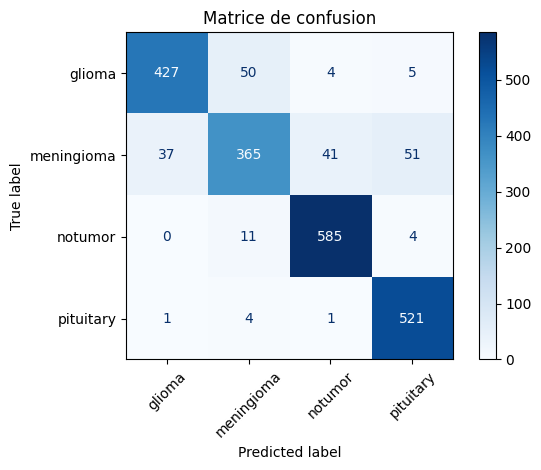

2026/10/25 14:43:49 WARNING mlflow.tensorflow: You are saving a TensorFlow Core model or Keras model without a signature. Inference with mlflow.pyfunc.spark_udf() will not work unless the model's pyfunc representation accepts pandas DataFrames as inference inputs.


              precision    recall  f1-score   support

      glioma       0.92      0.88      0.90       486
  meningioma       0.85      0.74      0.79       494
     notumor       0.93      0.97      0.95       600
   pituitary       0.90      0.99      0.94       527

    accuracy                           0.90      2107
   macro avg       0.90      0.90      0.89      2107
weighted avg       0.90      0.90      0.90      2107



Successfully registered model 'cnn'.
Created version '1' of model 'cnn'.


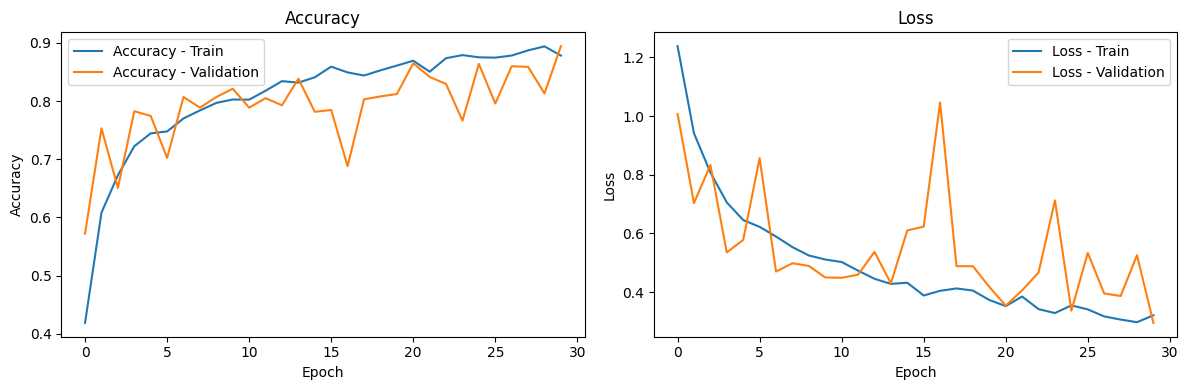

In [21]:
build_cnn_model(
    x_train=X_train,
    y_train = y_train,
    x_val = X_val,
    y_val = y_val,
    x_test = X_test,
    y_test = y_test,
    data_augmentation=data_augmentation,
    label_encoder=label_encoder
)

#### MobileNetV2

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ sequential (Sequential)         │ (1, 224, 224, 3)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (1, 7, 7, 1280)        │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (1, 1280)              │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (1, 128)               │       163,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (1, 128)               │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (1, 4)                 │           516 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,422,468 (9.24 MB)

 Trainable params: 164,484 (642.52 KB)

 Non-trainable params: 2,257,984 (8.61 MB)


========= Tresfer Learning =========

Epoch 1/30
88/88 ━━━━━━━━━━━━━━━━━━━━ 0s 55ms/step - accuracy: 0.6860 - loss: 0.7422
Epoch 1: val_loss improved from inf to 0.50286, saving model to output/models/mobilenetv2_1_00_224/best_model_tl.keras
88/88 ━━━━━━━━━━━━━━━━━━━━ 10s 84ms/step - accuracy: 0.6871 - loss: 0.7400 - val_accuracy: 0.7978 - val_loss: 0.5029
Epoch 2/30
87/88 ━━━━━━━━━━━━━━━━━━━━ 0s 55ms/step - accuracy: 0.8731 - loss: 0.3469
Epoch 2: val_loss improved from 0.50286 to 0.49174, saving model to output/models/mobilenetv2_1_00_224/best_model_tl.keras
88/88 ━━━━━━━━━━━━━━━━━━━━ 6s 74ms/step - accuracy: 0.8731 - loss: 0.3469 - val_accuracy: 0.7998 - val_loss: 0.4917
Epoch 3/30
87/88 ━━━━━━━━━━━━━━━━━━━━ 0s 55ms/step - accuracy: 0.8947 - loss: 0.3083
Epoch 3: val_loss did not improve from 0.49174
88/88 ━━━━━━━━━━━━━━━━━━━━ 6s 70ms/step - accuracy: 0.8945 - loss: 0.3084 - val_accuracy: 0.7876 - val_loss: 0.5394
Epoch 4/30
87/88 ━━━━━━━━━━━━━━━━━━━━ 0s 55ms/step - accuracy: 0.895

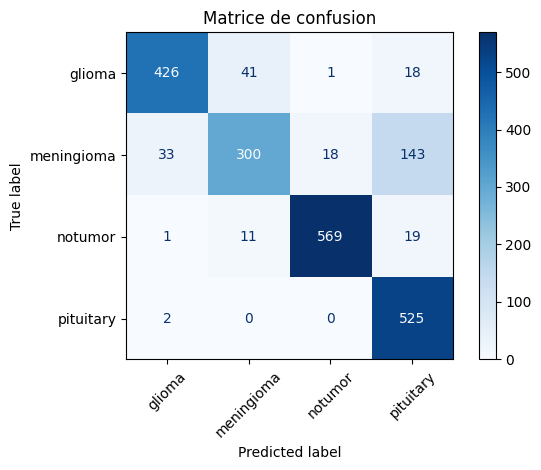

2026/10/25 14:46:43 WARNING mlflow.tensorflow: You are saving a TensorFlow Core model or Keras model without a signature. Inference with mlflow.pyfunc.spark_udf() will not work unless the model's pyfunc representation accepts pandas DataFrames as inference inputs.


              precision    recall  f1-score   support

      glioma       0.92      0.88      0.90       486
  meningioma       0.85      0.61      0.71       494
     notumor       0.97      0.95      0.96       600
   pituitary       0.74      1.00      0.85       527

    accuracy                           0.86      2107
   macro avg       0.87      0.86      0.85      2107
weighted avg       0.87      0.86      0.86      2107



Successfully registered model 'mobilenetv2_1_00_224_transfer_learning'.
Created version '1' of model 'mobilenetv2_1_00_224_transfer_learning'.


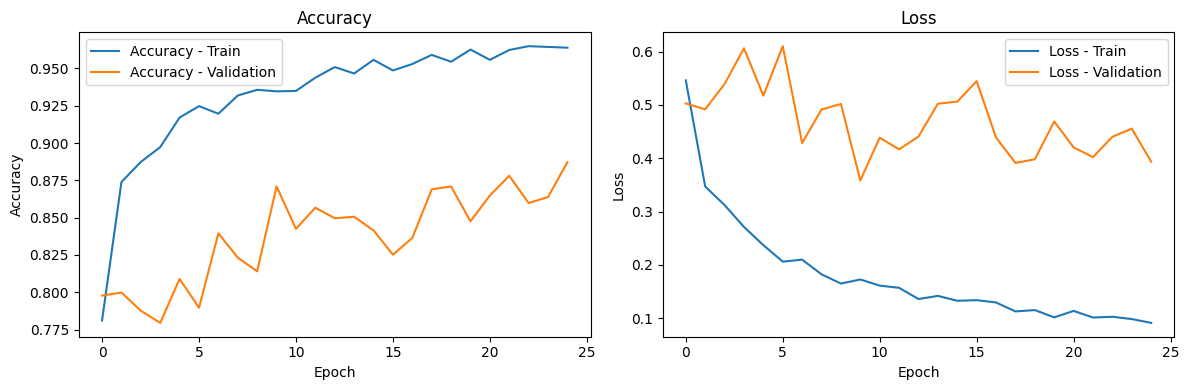


========= Fine Tuning =========

Epoch 1/30
88/88 ━━━━━━━━━━━━━━━━━━━━ 0s 77ms/step - accuracy: 0.9449 - loss: 0.1511
Epoch 1: val_loss improved from inf to 0.42558, saving model to output/models/mobilenetv2_1_00_224/best_model_ft.keras
88/88 ━━━━━━━━━━━━━━━━━━━━ 14s 105ms/step - accuracy: 0.9449 - loss: 0.1510 - val_accuracy: 0.8425 - val_loss: 0.4256
Epoch 2/30
87/88 ━━━━━━━━━━━━━━━━━━━━ 0s 65ms/step - accuracy: 0.9497 - loss: 0.1240
Epoch 2: val_loss improved from 0.42558 to 0.42038, saving model to output/models/mobilenetv2_1_00_224/best_model_ft.keras
88/88 ━━━━━━━━━━━━━━━━━━━━ 7s 84ms/step - accuracy: 0.9498 - loss: 0.1241 - val_accuracy: 0.8598 - val_loss: 0.4204
Epoch 3/30
87/88 ━━━━━━━━━━━━━━━━━━━━ 0s 65ms/step - accuracy: 0.9603 - loss: 0.1085
Epoch 3: val_loss improved from 0.42038 to 0.36975, saving model to output/models/mobilenetv2_1_00_224/best_model_ft.keras
88/88 ━━━━━━━━━━━━━━━━━━━━ 7s 84ms/step - accuracy: 0.9604 - loss: 0.1084 - val_accuracy: 0.8730 - val_loss: 0.3

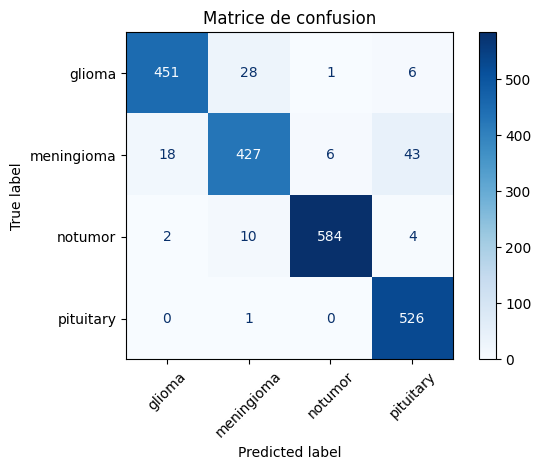

2026/10/25 14:50:37 WARNING mlflow.tensorflow: You are saving a TensorFlow Core model or Keras model without a signature. Inference with mlflow.pyfunc.spark_udf() will not work unless the model's pyfunc representation accepts pandas DataFrames as inference inputs.


              precision    recall  f1-score   support

      glioma       0.96      0.93      0.94       486
  meningioma       0.92      0.86      0.89       494
     notumor       0.99      0.97      0.98       600
   pituitary       0.91      1.00      0.95       527

    accuracy                           0.94      2107
   macro avg       0.94      0.94      0.94      2107
weighted avg       0.94      0.94      0.94      2107



Successfully registered model 'mobilenetv2_1_00_224_fine_tuning'.
Created version '1' of model 'mobilenetv2_1_00_224_fine_tuning'.


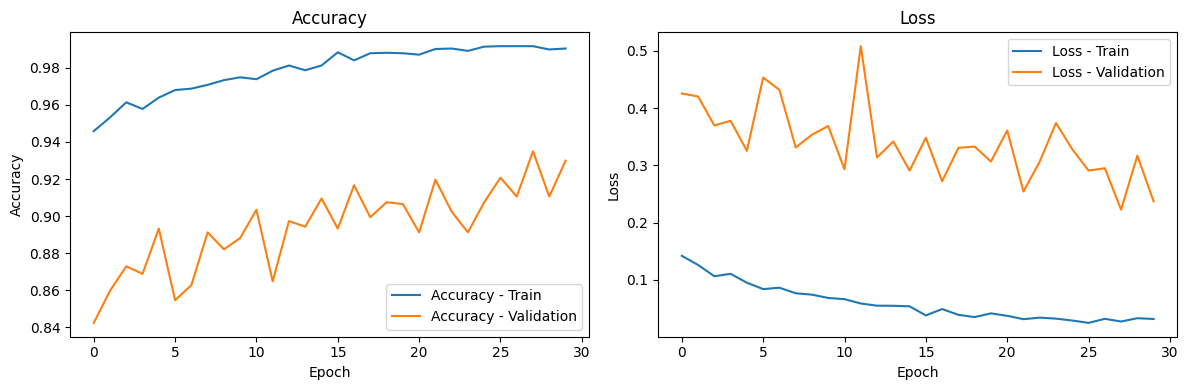

In [22]:
build_transfer_model(
    base_model=MobileNetV2,
    normalize_collback=preprocess_input,
    x_train=X_train,
    y_train = y_train,
    x_val = X_val,
    y_val = y_val,
    x_test = X_test,
    y_test = y_test,
    data_augmentation=data_augmentation,
    label_encoder=label_encoder
)


#### Champion

In [ ]:
def set_model_alias(model_name, model_version, alias="champion"):
    client = MlflowClient()
    client.set_registered_model_alias(
        name=model_name,
        alias=alias,
        version=model_version
    )

model_name = "mobilenetv2_1_00_224"
model_version = "2"
set_model_alias(model_name, model_version)

#### Example de loead champion

In [ ]:
def load_model_from_mlflow(model_name):
    model = mlflow.tensorflow.load_model(
        f"models:/{model_name}@champion"
    )
    return model

model_name = "mobilenetv2_1.00_224"
model = load_model_from_mlflow(model_name)

#### Créer une fonction predict_image()

In [ ]:
def predict_image(model, image_path, normalize_collback, label_encoder):
    image_path = Path(image_path)

    extention_allow = {".jpeg", ".jpg", ".bmp", ".png"}

    # Vérifier le fichier
    if not image_path.is_file():
        raise FileNotFoundError(
            f"Image introuvable : {image_path}"
        )

    # Vérifier l'extension
    if image_path.suffix.lower() not in extention_allow:
        raise ValueError("Format d'image non autorisé.")

    image, _ = load_image(str(image_path), '', normalize_collback)

    # Ajouter la dimension batch
    image = np.expand_dims(image, axis=0)

    # Prédiction
    probabilities = model.predict(image, verbose=0)

    # Index de la classe prédite
    predicted_index = int(np.argmax(probabilities))

    # Index vers nom de classe
    predicted_class = label_encoder.inverse_transform([predicted_index])[0] # Parce que inverse_transform retourne un tableau

    # Probabilité maximale
    confidence = float(probabilities[predicted_index])

    return predicted_class, confidence, probabilities
